# kumarathunge2019

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su
from sympy.physics.units.quantities import Quantity

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_Tk(T_leaf):
    return T_leaf + 273.15

def _derived_JVr(T_growth, T_home, JVr_a, JVr_b, JVr_c):
    return ((JVr_a) - (JVr_b * T_home)) - (JVr_c * ((T_growth) - (T_home)))

def _derived_EaV(T_growth, EaV_a, EaV_b):
    return EaV_a + EaV_b * T_growth

def _derived_dSV(T_growth, dSV_a, dSV_b):
    return (dSV_a) - (dSV_b * T_growth)

def _derived_dSJ(T_growth, T_home, dSJ_a, dSJ_b, dSJ_c):
    return ((dSJ_a) - (dSJ_b * T_home)) - (dSJ_c * ((T_growth) - (T_home)))

def _derived_Jmax25(Vcmax25, JVr):
    return Vcmax25 * JVr

def _derived_Vcmax(Vcmax25, R, Hd, Tk, EaV, dSV):
    return (Vcmax25 * np.exp((1000 * EaV * ((Tk) - (298.15))) / (298.15 * R * Tk)) * (1 + np.exp(((298.15 * dSV) - (Hd)) / (298.15 * R)))) / (1 + np.exp(((Tk * dSV) - (Hd)) / (Tk * R)))

def _derived_Jmax(R, Hd, EaJ, Tk, dSJ, Jmax25):
    return (Jmax25 * np.exp((1000 * EaJ * ((Tk) - (298.15))) / (298.15 * R * Tk)) * (1 + np.exp(((298.15 * dSJ) - (Hd)) / (298.15 * R)))) / (1 + np.exp(((Tk * dSJ) - (Hd)) / (Tk * R)))

def _derived_ToptV(R, Hd, EaV, dSV):
    return ((Hd) / ((dSV) - (R * np.log((1000 * EaV) / ((Hd) - (1000 * EaV)))))) - (273.15)

def _derived_ToptJ(R, Hd, EaJ, dSJ):
    return ((Hd) / ((dSJ) - (R * np.log((1000 * EaJ) / ((Hd) - (1000 * EaJ)))))) - (273.15)

def _derived_J(Q, alpha, theta, Jmax):
    return ((alpha * Q + Jmax) - (np.pow(((alpha * Q + Jmax) ** (2)) - (4 * theta * alpha * Q * Jmax), 1 / 2))) / (2 * theta)

def _derived_Gamma_star(R, Gamma_star25, E_gamma, Tk):
    return Gamma_star25 * np.exp((E_gamma * ((Tk) - (298.15))) / (298.15 * R * Tk))

def _derived_Kc(R, Kc25, Ec, Tk):
    return Kc25 * np.exp((Ec * ((Tk) - (298.15))) / (298.15 * R * Tk))

def _derived_Ko(R, Ko25, Eo, Tk):
    return Ko25 * np.exp((Eo * ((Tk) - (298.15))) / (298.15 * R * Tk))

def _derived_Wc(Ci, O_i, Vcmax, Kc, Ko):
    return (Vcmax * Ci) / (Ci + Kc * (1 + (O_i) / (Ko)))

def _derived_Wj(Ci, J, Gamma_star):
    return (J * Ci) / (4 * (Ci + 2 * Gamma_star))

def _derived_RL(T_leaf, T_growth, Vcmax25, rV_a, rV_b, Q10_RL):
    return Vcmax25 * ((rV_a) - (rV_b * T_growth)) * (Q10_RL) ** (((T_leaf) - (25)) / (10))

def _derived_Ac(Ci, Gamma_star, Wc):
    return Wc * ((1) - ((Gamma_star) / (Ci)))

def _derived_Aj(Ci, Gamma_star, Wj):
    return Wj * ((1) - ((Gamma_star) / (Ci)))

def _derived_A_net(Ci, Gamma_star, Wc, Wj, RL):
    return (min(Wc, Wj) * ((1) - ((Gamma_star) / (Ci)))) - (RL)

def _derived_A_net_h(theta_h, RL, Ac, Aj):
    return (((Ac + Aj) - (np.pow(((Ac + Aj) ** (2)) - (4 * theta_h * Ac * Aj), 1 / 2))) / (2 * theta_h)) - (RL)

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("T_leaf", 25, unit=Quantity("celsius", abbrev="°C"), display_name="T_leaf", tex_name="T", slider=Slider(min="5", max="45", step="0.5"))
    m.add_parameter("Ci", 275, unit=0.000001, display_name="Ci", tex_name="C_i", slider=Slider(min="100", max="1500", step="5"))
    m.add_parameter("Q", 1500, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Q", tex_name="Q", slider=Slider(min="0", max="2000", step="10"))
    m.add_parameter("O_i", 210, unit=0.001, display_name="O_i", tex_name="O_i", slider=Slider(min="0", max="400", step="5"))
    m.add_parameter("T_growth", 12.9, unit=Quantity("celsius", abbrev="°C"), display_name="T_growth", tex_name="T_{growth}", slider=Slider(min="0", max="35", step="0.5"))
    m.add_parameter("T_home", 23.8, unit=Quantity("celsius", abbrev="°C"), display_name="T_home", tex_name="T_{home}", slider=Slider(min="5", max="40", step="0.5"))
    m.add_parameter("Vcmax25", 39, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax25", tex_name="V_{cmax25}", slider=Slider(min="10", max="150", step="0.5"))
    m.add_parameter("alpha", 0.24, unit=None, tex_name="\\alpha")
    m.add_parameter("theta", 0.85, unit=None, tex_name="\\theta")
    m.add_parameter("R", 8.314, unit=su.joule/(su.kelvin*su.mol), tex_name="R")
    m.add_parameter("Hd", 200000, unit=su.joule/su.mol, tex_name="H_d")
    m.add_parameter("EaJ", 40.71, unit=su.joule*su.kilo/su.mol, tex_name="E_{aJ}")
    m.add_parameter("Kc25", 404.9, unit=0.000001, tex_name="K_{c,25}")
    m.add_parameter("Ec", 79430, unit=su.joule/su.mol, tex_name="E_c")
    m.add_parameter("Ko25", 278.4, unit=0.001, tex_name="K_{o,25}")
    m.add_parameter("Eo", 36380, unit=su.joule/su.mol, tex_name="E_o")
    m.add_parameter("Gamma_star25", 42.75, unit=0.000001, tex_name="\\Gamma^\\ast_{25}")
    m.add_parameter("E_gamma", 37830, unit=su.joule/su.mol, tex_name="E_{\\Gamma^\\ast}")
    m.add_parameter("rV_a", 0.0326, unit=None, tex_name="r_{V,a}")
    m.add_parameter("rV_b", 0.0006, unit=1/Quantity("celsius", abbrev="°C"), tex_name="r_{V,b}")
    m.add_parameter("Q10_RL", 1.2515, unit=None, tex_name="Q_{10,R_L}")
    m.add_parameter("theta_h", 0.9999, unit=None, tex_name="\\theta_h")
    m.add_parameter("JVr_a", 2.56, unit=None, tex_name="a_{JV_r}")
    m.add_parameter("JVr_b", 0.0375, unit=1/Quantity("celsius", abbrev="°C"), tex_name="b_{JV_r}")
    m.add_parameter("JVr_c", 0.0202, unit=1/Quantity("celsius", abbrev="°C"), tex_name="c_{JV_r}")
    m.add_parameter("EaV_a", 42.6, unit=su.joule*su.kilo/su.mol, tex_name="a_{E_{aV}}")
    m.add_parameter("EaV_b", 1.14, unit=su.joule*su.kilo/(su.mol*Quantity("celsius", abbrev="°C")), tex_name="b_{E_{aV}}")
    m.add_parameter("dSV_a", 645.13, unit=su.joule/(su.kelvin*su.mol), tex_name="a_{\\Delta S_V}")
    m.add_parameter("dSV_b", 0.38, unit=su.joule/(su.kelvin*su.mol*Quantity("celsius", abbrev="°C")), tex_name="b_{\\Delta S_V}")
    m.add_parameter("dSJ_a", 658.77, unit=su.joule/(su.kelvin*su.mol), tex_name="a_{\\Delta S_J}")
    m.add_parameter("dSJ_b", 0.84, unit=su.joule/(su.kelvin*su.mol*Quantity("celsius", abbrev="°C")), tex_name="b_{\\Delta S_J}")
    m.add_parameter("dSJ_c", 0.52, unit=su.joule/(su.kelvin*su.mol*Quantity("celsius", abbrev="°C")), tex_name="c_{\\Delta S_J}")
    m.add_derived("Tk", _derived_Tk, args=["T_leaf"], unit=su.kelvin, tex_name="T_k")
    m.add_derived("JVr", _derived_JVr, args=["T_growth", "T_home", "JVr_a", "JVr_b", "JVr_c"], unit=None, display_name="JVr", tex_name="JV_r")
    m.add_derived("EaV", _derived_EaV, args=["T_growth", "EaV_a", "EaV_b"], unit=su.joule*su.kilo/su.mol, display_name="EaV", tex_name="E_{aV}")
    m.add_derived("dSV", _derived_dSV, args=["T_growth", "dSV_a", "dSV_b"], unit=su.joule/(su.kelvin*su.mol), display_name="dSV", tex_name="\\Delta S_V")
    m.add_derived("dSJ", _derived_dSJ, args=["T_growth", "T_home", "dSJ_a", "dSJ_b", "dSJ_c"], unit=su.joule/(su.kelvin*su.mol), display_name="dSJ", tex_name="\\Delta S_J")
    m.add_derived("Jmax25", _derived_Jmax25, args=["Vcmax25", "JVr"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax25", tex_name="J_{max25}")
    m.add_derived("Vcmax", _derived_Vcmax, args=["Vcmax25", "R", "Hd", "Tk", "EaV", "dSV"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax", tex_name="V_{cmax}")
    m.add_derived("Jmax", _derived_Jmax, args=["R", "Hd", "EaJ", "Tk", "dSJ", "Jmax25"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax", tex_name="J_{max}")
    m.add_derived("ToptV", _derived_ToptV, args=["R", "Hd", "EaV", "dSV"], unit=Quantity("celsius", abbrev="°C"), display_name="ToptV", tex_name="T_{optV}")
    m.add_derived("ToptJ", _derived_ToptJ, args=["R", "Hd", "EaJ", "dSJ"], unit=Quantity("celsius", abbrev="°C"), display_name="ToptJ", tex_name="T_{optJ}")
    m.add_derived("J", _derived_J, args=["Q", "alpha", "theta", "Jmax"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J", tex_name="J")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["R", "Gamma_star25", "E_gamma", "Tk"], unit=0.000001, display_name="Gamma_star", tex_name="\\Gamma^\\ast")
    m.add_derived("Kc", _derived_Kc, args=["R", "Kc25", "Ec", "Tk"], unit=0.000001, display_name="Kc", tex_name="K_c")
    m.add_derived("Ko", _derived_Ko, args=["R", "Ko25", "Eo", "Tk"], unit=0.001, display_name="Ko", tex_name="K_o")
    m.add_derived("Wc", _derived_Wc, args=["Ci", "O_i", "Vcmax", "Kc", "Ko"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wc", tex_name="W_c")
    m.add_derived("Wj", _derived_Wj, args=["Ci", "J", "Gamma_star"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wj", tex_name="W_j")
    m.add_derived("RL", _derived_RL, args=["T_leaf", "T_growth", "Vcmax25", "rV_a", "rV_b", "Q10_RL"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="RL", tex_name="R_L")
    m.add_derived("Ac", _derived_Ac, args=["Ci", "Gamma_star", "Wc"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac", tex_name="A_c")
    m.add_derived("Aj", _derived_Aj, args=["Ci", "Gamma_star", "Wj"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Aj", tex_name="A_j")
    m.add_derived("A_net", _derived_A_net, args=["Ci", "Gamma_star", "Wc", "Wj", "RL"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_net", tex_name="A_{net}")
    m.add_derived("A_net_h", _derived_A_net_h, args=["theta_h", "RL", "Ac", "Aj"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_net_h", tex_name="A_{net,h}")
    return m


## Figure 7a: predicted against observed ToptA275, acclimation and adaptation (Table 2)

In [3]:
data = {"obs":[21.312,27.603,26.041,31.904,26.114,19.849,22.15,24.443,17.506,27.851,22.718,28.877,31.801,32.246,33.469,31.512,32.281,20.917],"se":[1.335,1.195,5.21,0.334,4.386,0.699,1.269,0.447,0.214,2.961,0.791,1.05,2.234,1.648,0.493,2.803,1.629,2.929],"identity":[14,36],"fitX":[17.5,33],"fitY":[16.875000000000004,33.77]}
data = {k: np.array(c) for k, c in data.items()}
tables = {}

# Scan a0
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 12.9, "T_home": 23.8, "Vcmax25": 39.043, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a0"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a1
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 17.1333, "T_home": 28.9, "Vcmax25": 82.9746, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a1"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a2
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 21.9957, "T_home": 34.5, "Vcmax25": 82.9746, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a2"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a3
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 27.1315, "T_home": 37.8, "Vcmax25": 39.4524, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a3"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a4
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 11.78, "T_home": 22.9, "Vcmax25": 82.9746, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a4"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a5
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 5.3383, "T_home": 25.8, "Vcmax25": 80.4005, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a5"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a6
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 9.3778, "T_home": 20.1, "Vcmax25": 80.4005, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a6"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a7
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 15.4, "T_home": 20.1, "Vcmax25": 80.4005, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a7"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a8
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 14, "T_home": 20.4, "Vcmax25": 80.4005, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a8"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a9
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 26.4036, "T_home": 31.4, "Vcmax25": 42.8136, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a9"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a10
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 11.85, "T_home": 26, "Vcmax25": 42.8136, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a10"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a11
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 20.9629, "T_home": 26.7, "Vcmax25": 42.8136, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a11"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a12
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 24.0083, "T_home": 29.8, "Vcmax25": 39.4524, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a12"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a13
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 24.0083, "T_home": 29.8, "Vcmax25": 39.4524, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a13"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a14
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 26.9, "T_home": 32.6, "Vcmax25": 39.4524, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a14"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a15
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 25.8, "T_home": 32.7, "Vcmax25": 39.4524, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a15"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a16
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 27.5283, "T_home": 31.3, "Vcmax25": 39.4524, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a16"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan a17
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 3.1, "T_home": 7.7, "Vcmax25": 78.3006, "JVr_a": 2.55684, "JVr_b": 0.03707, "JVr_c": 0.02019, "dSJ_a": 658.7761, "dSJ_b": 0.8431, "dSJ_c": 0.5194, "EaJ": 40.71109})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["a17"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3522.79it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3889.96it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3898.05it/s]

... (26 outputs left out)

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3929.70it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3773.96it/s]

In [4]:
tables["topt_a"] = {"x": np.linspace(0, 17, 18), "pred": np.array([np.asarray(tables["a0"]["x"])[np.argmin(np.abs(np.asarray(tables["a0"]["A_net_h"]) - np.max(tables["a0"]["A_net_h"])))], np.asarray(tables["a1"]["x"])[np.argmin(np.abs(np.asarray(tables["a1"]["A_net_h"]) - np.max(tables["a1"]["A_net_h"])))], np.asarray(tables["a2"]["x"])[np.argmin(np.abs(np.asarray(tables["a2"]["A_net_h"]) - np.max(tables["a2"]["A_net_h"])))], np.asarray(tables["a3"]["x"])[np.argmin(np.abs(np.asarray(tables["a3"]["A_net_h"]) - np.max(tables["a3"]["A_net_h"])))], np.asarray(tables["a4"]["x"])[np.argmin(np.abs(np.asarray(tables["a4"]["A_net_h"]) - np.max(tables["a4"]["A_net_h"])))], np.asarray(tables["a5"]["x"])[np.argmin(np.abs(np.asarray(tables["a5"]["A_net_h"]) - np.max(tables["a5"]["A_net_h"])))], np.asarray(tables["a6"]["x"])[np.argmin(np.abs(np.asarray(tables["a6"]["A_net_h"]) - np.max(tables["a6"]["A_net_h"])))], np.asarray(tables["a7"]["x"])[np.argmin(np.abs(np.asarray(tables["a7"]["A_net_h"]) - np.max(tables["a7"]["A_net_h"])))], np.asarray(tables["a8"]["x"])[np.argmin(np.abs(np.asarray(tables["a8"]["A_net_h"]) - np.max(tables["a8"]["A_net_h"])))], np.asarray(tables["a9"]["x"])[np.argmin(np.abs(np.asarray(tables["a9"]["A_net_h"]) - np.max(tables["a9"]["A_net_h"])))], np.asarray(tables["a10"]["x"])[np.argmin(np.abs(np.asarray(tables["a10"]["A_net_h"]) - np.max(tables["a10"]["A_net_h"])))], np.asarray(tables["a11"]["x"])[np.argmin(np.abs(np.asarray(tables["a11"]["A_net_h"]) - np.max(tables["a11"]["A_net_h"])))], np.asarray(tables["a12"]["x"])[np.argmin(np.abs(np.asarray(tables["a12"]["A_net_h"]) - np.max(tables["a12"]["A_net_h"])))], np.asarray(tables["a13"]["x"])[np.argmin(np.abs(np.asarray(tables["a13"]["A_net_h"]) - np.max(tables["a13"]["A_net_h"])))], np.asarray(tables["a14"]["x"])[np.argmin(np.abs(np.asarray(tables["a14"]["A_net_h"]) - np.max(tables["a14"]["A_net_h"])))], np.asarray(tables["a15"]["x"])[np.argmin(np.abs(np.asarray(tables["a15"]["A_net_h"]) - np.max(tables["a15"]["A_net_h"])))], np.asarray(tables["a16"]["x"])[np.argmin(np.abs(np.asarray(tables["a16"]["A_net_h"]) - np.max(tables["a16"]["A_net_h"])))], np.asarray(tables["a17"]["x"])[np.argmin(np.abs(np.asarray(tables["a17"]["A_net_h"]) - np.max(tables["a17"]["A_net_h"])))]])}

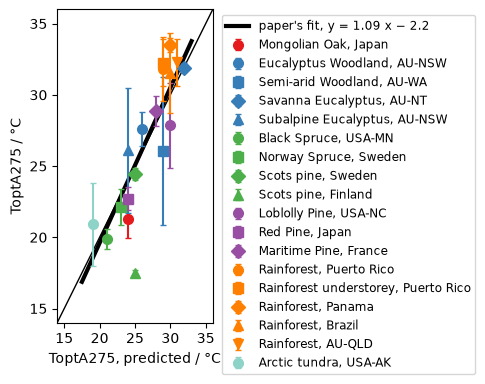

In [5]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(data["identity"], data["identity"], color="black", lw=1)
ax0.plot(data["fitX"], data["fitY"], color="black", lw=3, label="paper's fit, y = 1.09 x − 2.2")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(0):int(1)], np.asarray(data["obs"])[int(0):int(1)], yerr=np.asarray(data["se"])[int(0):int(1)], color="#E41A1C", ls="none", marker="o", markersize=7, capsize=2, label="Mongolian Oak, Japan")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(1):int(2)], np.asarray(data["obs"])[int(1):int(2)], yerr=np.asarray(data["se"])[int(1):int(2)], color="#377EB8", ls="none", marker="o", markersize=7, capsize=2, label="Eucalyptus Woodland, AU-NSW")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(2):int(3)], np.asarray(data["obs"])[int(2):int(3)], yerr=np.asarray(data["se"])[int(2):int(3)], color="#377EB8", ls="none", marker="s", markersize=7, capsize=2, label="Semi-arid Woodland, AU-WA")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(3):int(4)], np.asarray(data["obs"])[int(3):int(4)], yerr=np.asarray(data["se"])[int(3):int(4)], color="#377EB8", ls="none", marker="D", markersize=7, capsize=2, label="Savanna Eucalyptus, AU-NT")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(4):int(5)], np.asarray(data["obs"])[int(4):int(5)], yerr=np.asarray(data["se"])[int(4):int(5)], color="#377EB8", ls="none", marker="^", markersize=7, capsize=2, label="Subalpine Eucalyptus, AU-NSW")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(5):int(6)], np.asarray(data["obs"])[int(5):int(6)], yerr=np.asarray(data["se"])[int(5):int(6)], color="#4DAF4A", ls="none", marker="o", markersize=7, capsize=2, label="Black Spruce, USA-MN")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(6):int(7)], np.asarray(data["obs"])[int(6):int(7)], yerr=np.asarray(data["se"])[int(6):int(7)], color="#4DAF4A", ls="none", marker="s", markersize=7, capsize=2, label="Norway Spruce, Sweden")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(7):int(8)], np.asarray(data["obs"])[int(7):int(8)], yerr=np.asarray(data["se"])[int(7):int(8)], color="#4DAF4A", ls="none", marker="D", markersize=7, capsize=2, label="Scots pine, Sweden")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(8):int(9)], np.asarray(data["obs"])[int(8):int(9)], yerr=np.asarray(data["se"])[int(8):int(9)], color="#4DAF4A", ls="none", marker="^", markersize=7, capsize=2, label="Scots pine, Finland")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(9):int(10)], np.asarray(data["obs"])[int(9):int(10)], yerr=np.asarray(data["se"])[int(9):int(10)], color="#984EA3", ls="none", marker="o", markersize=7, capsize=2, label="Loblolly Pine, USA-NC")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(10):int(11)], np.asarray(data["obs"])[int(10):int(11)], yerr=np.asarray(data["se"])[int(10):int(11)], color="#984EA3", ls="none", marker="s", markersize=7, capsize=2, label="Red Pine, Japan")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(11):int(12)], np.asarray(data["obs"])[int(11):int(12)], yerr=np.asarray(data["se"])[int(11):int(12)], color="#984EA3", ls="none", marker="D", markersize=7, capsize=2, label="Maritime Pine, France")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(12):int(13)], np.asarray(data["obs"])[int(12):int(13)], yerr=np.asarray(data["se"])[int(12):int(13)], color="#FF7F00", ls="none", marker="o", markersize=7, capsize=2, label="Rainforest, Puerto Rico")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(13):int(14)], np.asarray(data["obs"])[int(13):int(14)], yerr=np.asarray(data["se"])[int(13):int(14)], color="#FF7F00", ls="none", marker="s", markersize=7, capsize=2, label="Rainforest understorey, Puerto Rico")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(14):int(15)], np.asarray(data["obs"])[int(14):int(15)], yerr=np.asarray(data["se"])[int(14):int(15)], color="#FF7F00", ls="none", marker="D", markersize=7, capsize=2, label="Rainforest, Panama")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(15):int(16)], np.asarray(data["obs"])[int(15):int(16)], yerr=np.asarray(data["se"])[int(15):int(16)], color="#FF7F00", ls="none", marker="^", markersize=7, capsize=2, label="Rainforest, Brazil")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(16):int(17)], np.asarray(data["obs"])[int(16):int(17)], yerr=np.asarray(data["se"])[int(16):int(17)], color="#FF7F00", ls="none", marker="v", markersize=7, capsize=2, label="Rainforest, AU-QLD")
ax0.errorbar(np.asarray(tables["topt_a"]["pred"])[int(17):int(18)], np.asarray(data["obs"])[int(17):int(18)], yerr=np.asarray(data["se"])[int(17):int(18)], color="#8DD3C7", ls="none", marker="o", markersize=7, capsize=2, label="Arctic tundra, USA-AK")
ax0.set_xlabel("ToptA275, predicted / °C")
ax0.set_ylabel("ToptA275 / °C")
ax0.set_xlim(14, 36)
ax0.set_ylim(14, 36)
ax0.set_xticks([15,20,25,30,35])
ax0.set_yticks([15,20,25,30,35])
ax0.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize="small")
plt.tight_layout()
plt.show()

## Figure 7b: predicted against observed ToptA275, Kattge & Knorr (2007)

In [6]:
data = {"obs":[21.312,27.603,26.041,31.904,26.114,19.849,22.15,24.443,17.506,27.851,22.718,28.877,31.801,32.246,33.469,31.512,32.281,20.917],"se":[1.335,1.195,5.21,0.334,4.386,0.699,1.269,0.447,0.214,2.961,0.791,1.05,2.234,1.648,0.493,2.803,1.629,2.929],"identity":[14,36],"fitX":[20,30.5],"fitY":[17.78,34.370000000000005]}
data = {k: np.array(c) for k, c in data.items()}
tables = {}

# Scan b0
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 12.9, "T_home": 23.8, "Vcmax25": 39.043, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.0320800143431601})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b0"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b1
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 17.1333, "T_home": 28.9, "Vcmax25": 82.9746, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.013842790444304644})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b1"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b2
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 21.9957, "T_home": 34.5, "Vcmax25": 82.9746, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.015693959356236728})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b2"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b3
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 27.1315, "T_home": 37.8, "Vcmax25": 39.4524, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.010562095081668036})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b3"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b4
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 11.78, "T_home": 22.9, "Vcmax25": 82.9746, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.027073345337006748})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b4"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b5
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 5.3383, "T_home": 25.8, "Vcmax25": 80.4005, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.025132928277809222})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b5"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b6
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 9.3778, "T_home": 20.1, "Vcmax25": 80.4005, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.014016081989539868})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b6"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b7
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 15.4, "T_home": 20.1, "Vcmax25": 80.4005, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.027788384400594526})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b7"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b8
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 14, "T_home": 20.4, "Vcmax25": 80.4005, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.043809429045839274})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b8"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b9
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 26.4036, "T_home": 31.4, "Vcmax25": 42.8136, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.012776314068426855})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b9"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b10
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 11.85, "T_home": 26, "Vcmax25": 42.8136, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.023936319300409212})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b10"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b11
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 20.9629, "T_home": 26.7, "Vcmax25": 42.8136, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.0068693125548891})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b11"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b12
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 24.0083, "T_home": 29.8, "Vcmax25": 39.4524, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.020936622360109906})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b12"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b13
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 24.0083, "T_home": 29.8, "Vcmax25": 39.4524, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.056103050764972476})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b13"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b14
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 26.9, "T_home": 32.6, "Vcmax25": 39.4524, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.014156299743488357})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b14"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b15
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 25.8, "T_home": 32.7, "Vcmax25": 39.4524, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.014604941651205})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b15"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b16
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 27.5283, "T_home": 31.3, "Vcmax25": 39.4524, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.015578266467946186})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b16"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

# Scan b17
to_scan = pd.DataFrame({"T_leaf": np.linspace(15, 35, 21), "T_growth": 3.1, "T_home": 7.7, "Vcmax25": 78.3006, "EaV_a": 72, "EaV_b": 0, "dSV_a": 668.39, "dSV_b": 1.07, "EaJ": 50, "JVr_a": 2.59, "JVr_b": 0.035, "JVr_c": 0.035, "dSJ_a": 659.7, "dSJ_b": 0.75, "dSJ_c": 0.75, "rV_b": 0, "rV_a": 0.03261405404300861})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_net_h"]].isna().any(axis=None)
tables["b17"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "A_net_h": frame["A_net_h"].to_numpy(),
}

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3438.22it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3635.78it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3628.89it/s]

... (26 outputs left out)

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3871.32it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 3919.04it/s]

In [7]:
tables["topt_b"] = {"x": np.linspace(0, 17, 18), "pred": np.array([np.asarray(tables["b0"]["x"])[np.argmin(np.abs(np.asarray(tables["b0"]["A_net_h"]) - np.max(tables["b0"]["A_net_h"])))], np.asarray(tables["b1"]["x"])[np.argmin(np.abs(np.asarray(tables["b1"]["A_net_h"]) - np.max(tables["b1"]["A_net_h"])))], np.asarray(tables["b2"]["x"])[np.argmin(np.abs(np.asarray(tables["b2"]["A_net_h"]) - np.max(tables["b2"]["A_net_h"])))], np.asarray(tables["b3"]["x"])[np.argmin(np.abs(np.asarray(tables["b3"]["A_net_h"]) - np.max(tables["b3"]["A_net_h"])))], np.asarray(tables["b4"]["x"])[np.argmin(np.abs(np.asarray(tables["b4"]["A_net_h"]) - np.max(tables["b4"]["A_net_h"])))], np.asarray(tables["b5"]["x"])[np.argmin(np.abs(np.asarray(tables["b5"]["A_net_h"]) - np.max(tables["b5"]["A_net_h"])))], np.asarray(tables["b6"]["x"])[np.argmin(np.abs(np.asarray(tables["b6"]["A_net_h"]) - np.max(tables["b6"]["A_net_h"])))], np.asarray(tables["b7"]["x"])[np.argmin(np.abs(np.asarray(tables["b7"]["A_net_h"]) - np.max(tables["b7"]["A_net_h"])))], np.asarray(tables["b8"]["x"])[np.argmin(np.abs(np.asarray(tables["b8"]["A_net_h"]) - np.max(tables["b8"]["A_net_h"])))], np.asarray(tables["b9"]["x"])[np.argmin(np.abs(np.asarray(tables["b9"]["A_net_h"]) - np.max(tables["b9"]["A_net_h"])))], np.asarray(tables["b10"]["x"])[np.argmin(np.abs(np.asarray(tables["b10"]["A_net_h"]) - np.max(tables["b10"]["A_net_h"])))], np.asarray(tables["b11"]["x"])[np.argmin(np.abs(np.asarray(tables["b11"]["A_net_h"]) - np.max(tables["b11"]["A_net_h"])))], np.asarray(tables["b12"]["x"])[np.argmin(np.abs(np.asarray(tables["b12"]["A_net_h"]) - np.max(tables["b12"]["A_net_h"])))], np.asarray(tables["b13"]["x"])[np.argmin(np.abs(np.asarray(tables["b13"]["A_net_h"]) - np.max(tables["b13"]["A_net_h"])))], np.asarray(tables["b14"]["x"])[np.argmin(np.abs(np.asarray(tables["b14"]["A_net_h"]) - np.max(tables["b14"]["A_net_h"])))], np.asarray(tables["b15"]["x"])[np.argmin(np.abs(np.asarray(tables["b15"]["A_net_h"]) - np.max(tables["b15"]["A_net_h"])))], np.asarray(tables["b16"]["x"])[np.argmin(np.abs(np.asarray(tables["b16"]["A_net_h"]) - np.max(tables["b16"]["A_net_h"])))], np.asarray(tables["b17"]["x"])[np.argmin(np.abs(np.asarray(tables["b17"]["A_net_h"]) - np.max(tables["b17"]["A_net_h"])))]])}

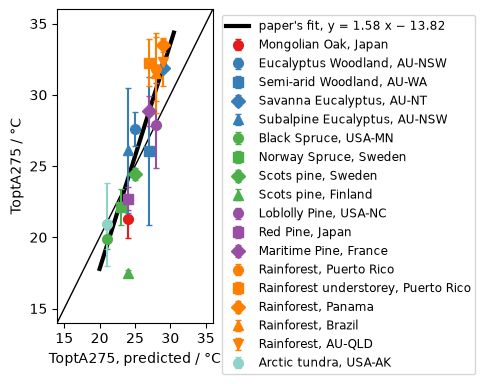

In [8]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(data["identity"], data["identity"], color="black", lw=1)
ax0.plot(data["fitX"], data["fitY"], color="black", lw=3, label="paper's fit, y = 1.58 x − 13.82")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(0):int(1)], np.asarray(data["obs"])[int(0):int(1)], yerr=np.asarray(data["se"])[int(0):int(1)], color="#E41A1C", ls="none", marker="o", markersize=7, capsize=2, label="Mongolian Oak, Japan")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(1):int(2)], np.asarray(data["obs"])[int(1):int(2)], yerr=np.asarray(data["se"])[int(1):int(2)], color="#377EB8", ls="none", marker="o", markersize=7, capsize=2, label="Eucalyptus Woodland, AU-NSW")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(2):int(3)], np.asarray(data["obs"])[int(2):int(3)], yerr=np.asarray(data["se"])[int(2):int(3)], color="#377EB8", ls="none", marker="s", markersize=7, capsize=2, label="Semi-arid Woodland, AU-WA")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(3):int(4)], np.asarray(data["obs"])[int(3):int(4)], yerr=np.asarray(data["se"])[int(3):int(4)], color="#377EB8", ls="none", marker="D", markersize=7, capsize=2, label="Savanna Eucalyptus, AU-NT")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(4):int(5)], np.asarray(data["obs"])[int(4):int(5)], yerr=np.asarray(data["se"])[int(4):int(5)], color="#377EB8", ls="none", marker="^", markersize=7, capsize=2, label="Subalpine Eucalyptus, AU-NSW")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(5):int(6)], np.asarray(data["obs"])[int(5):int(6)], yerr=np.asarray(data["se"])[int(5):int(6)], color="#4DAF4A", ls="none", marker="o", markersize=7, capsize=2, label="Black Spruce, USA-MN")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(6):int(7)], np.asarray(data["obs"])[int(6):int(7)], yerr=np.asarray(data["se"])[int(6):int(7)], color="#4DAF4A", ls="none", marker="s", markersize=7, capsize=2, label="Norway Spruce, Sweden")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(7):int(8)], np.asarray(data["obs"])[int(7):int(8)], yerr=np.asarray(data["se"])[int(7):int(8)], color="#4DAF4A", ls="none", marker="D", markersize=7, capsize=2, label="Scots pine, Sweden")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(8):int(9)], np.asarray(data["obs"])[int(8):int(9)], yerr=np.asarray(data["se"])[int(8):int(9)], color="#4DAF4A", ls="none", marker="^", markersize=7, capsize=2, label="Scots pine, Finland")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(9):int(10)], np.asarray(data["obs"])[int(9):int(10)], yerr=np.asarray(data["se"])[int(9):int(10)], color="#984EA3", ls="none", marker="o", markersize=7, capsize=2, label="Loblolly Pine, USA-NC")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(10):int(11)], np.asarray(data["obs"])[int(10):int(11)], yerr=np.asarray(data["se"])[int(10):int(11)], color="#984EA3", ls="none", marker="s", markersize=7, capsize=2, label="Red Pine, Japan")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(11):int(12)], np.asarray(data["obs"])[int(11):int(12)], yerr=np.asarray(data["se"])[int(11):int(12)], color="#984EA3", ls="none", marker="D", markersize=7, capsize=2, label="Maritime Pine, France")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(12):int(13)], np.asarray(data["obs"])[int(12):int(13)], yerr=np.asarray(data["se"])[int(12):int(13)], color="#FF7F00", ls="none", marker="o", markersize=7, capsize=2, label="Rainforest, Puerto Rico")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(13):int(14)], np.asarray(data["obs"])[int(13):int(14)], yerr=np.asarray(data["se"])[int(13):int(14)], color="#FF7F00", ls="none", marker="s", markersize=7, capsize=2, label="Rainforest understorey, Puerto Rico")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(14):int(15)], np.asarray(data["obs"])[int(14):int(15)], yerr=np.asarray(data["se"])[int(14):int(15)], color="#FF7F00", ls="none", marker="D", markersize=7, capsize=2, label="Rainforest, Panama")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(15):int(16)], np.asarray(data["obs"])[int(15):int(16)], yerr=np.asarray(data["se"])[int(15):int(16)], color="#FF7F00", ls="none", marker="^", markersize=7, capsize=2, label="Rainforest, Brazil")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(16):int(17)], np.asarray(data["obs"])[int(16):int(17)], yerr=np.asarray(data["se"])[int(16):int(17)], color="#FF7F00", ls="none", marker="v", markersize=7, capsize=2, label="Rainforest, AU-QLD")
ax0.errorbar(np.asarray(tables["topt_b"]["pred"])[int(17):int(18)], np.asarray(data["obs"])[int(17):int(18)], yerr=np.asarray(data["se"])[int(17):int(18)], color="#8DD3C7", ls="none", marker="o", markersize=7, capsize=2, label="Arctic tundra, USA-AK")
ax0.set_xlabel("ToptA275, predicted / °C")
ax0.set_ylabel("ToptA275 / °C")
ax0.set_xlim(14, 36)
ax0.set_ylim(14, 36)
ax0.set_xticks([15,20,25,30,35])
ax0.set_yticks([15,20,25,30,35])
ax0.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize="small")
plt.tight_layout()
plt.show()